# KAN on Pd-catalyzed direct arylation with continuous conditions

**Source.** Shields, Stevens, Li, Parasram, Damani, Martinez Alvarado, Janey, Adams, Doyle,
*Nature* **2021**, *590*, 89-96 (DOI 10.1038/s41586-021-03213-y), the dataset used to benchmark
Bayesian reaction optimization. Files from the `edbo` package (`direct_arylation/`): the
experiment index and the DFT descriptor tables for ligands (Boltzmann-averaged), bases and
solvents.

**Reaction.** Pd-catalyzed C-H arylation of an imidazole with an aryl bromide over a full
factorial of 12 phosphine ligands, 4 carboxylate bases (KOAc, KOPiv, CsOAc, CsOPiv),
4 solvents (DMAc, BuCN, BuOAc, *p*-xylene), 3 concentrations (0.057, 0.100, 0.153 M) and
3 temperatures (90, 105, 120 °C): 1728 reactions.

**Why it is a useful test.** This is the first dataset in the series whose variables include
reaction conditions rather than only molecule labels. Temperature and concentration are physical
quantities, so their effect can be held against a rate law, although each was sampled at only
three levels, which is a table of three means rather than a curve. The C-H activation step is a
concerted metalation-deprotonation in which the carboxylate base sits in the transition state, so
base identity (pivalate against acetate, cesium against potassium) is expected to matter more
than its size descriptors alone would suggest.

**Descriptors used here.** Temperature and concentration as given; six Boltzmann-averaged ligand
descriptors (percent buried volume at P, HOMO, LUMO, hardness, dipole, molar volume); four for the
base (dipole, molar volume, HOMO, LUMO) and four for the solvent (dipole, molar volume, HOMO,
LUMO). With four bases and four solvents, three independent effects each is the ceiling.

**Target.** Yield in percent, regression. Success for the threshold rules: above 20 % yield.

A caution that applies to the temperature reading below: these are yields after a fixed time, not
rate constants. A yield that has not saturated is roughly proportional to rate, so an Arrhenius
plot of the three temperature means gives an apparent barrier, not a measured activation energy.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Response curves that survive refitting.** Near-duplicate descriptors are pruned first, so
   an effect is not split between interchangeable columns. Each top descriptor then gets an
   accumulated local effect curve in its own units, with the linear baseline and the envelope
   of five refits, and the location of any step or window edge. A shape that changes from
   fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    accumulated_local_effects,
    accumulated_local_effects_cv,
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    prune_collinear,
    sensitivity,
    threshold_rules,
    transitions,
)
from pycse.sklearn._plotstyle import (
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Load the experiment index and join the component descriptors

The join keys are the SMILES strings in the index, which match the descriptor tables exactly.


In [2]:
BASE = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/direct_arylation/"
idx = pd.read_csv(BASE + "experiment_index.csv")
lig = pd.read_csv(BASE + "ligand-boltzmann_dft.csv")
bas = pd.read_csv(BASE + "base_dft.csv")
sol = pd.read_csv(BASE + "solvent_dft.csv")

LIG = {
    "ligand_pct_Vbur_P": "ligand_atom1_%VBur_Boltz", "ligand_E_HOMO": "ligand_homo_energy_Boltz",
    "ligand_E_LUMO": "ligand_lumo_energy_Boltz", "ligand_hardness": "ligand_hardness_Boltz",
    "ligand_dipole": "ligand_dipole_Boltz", "ligand_molar_volume": "ligand_molar_volume_Boltz",
}  # fmt: skip
BAS = {"base_dipole": "base_dipole", "base_molar_volume": "base_molar_volume", "base_E_HOMO": "base_homo_energy", "base_E_LUMO": "base_lumo_energy"}
SOL = {"solvent_dipole": "solvent_dipole", "solvent_molar_volume": "solvent_molar_volume", "solvent_E_HOMO": "solvent_homo_energy", "solvent_E_LUMO": "solvent_lumo_energy"}

df = idx.merge(lig[["ligand_SMILES", "ligand_file_name", *LIG.values()]].rename(columns={"ligand_SMILES": "Ligand_SMILES"}), on="Ligand_SMILES", how="left")
df = df.merge(bas[["base_SMILES", "base_file_name", *BAS.values()]].rename(columns={"base_SMILES": "Base_SMILES"}), on="Base_SMILES", how="left")
df = df.merge(sol[["solvent_SMILES", "solvent_file_name", *SOL.values()]].rename(columns={"solvent_SMILES": "Solvent_SMILES"}), on="Solvent_SMILES", how="left")
assert df[list(LIG.values())].notna().all().all() and len(df) == len(idx)
df["ligand_pct_Vbur_P"] = 100.0 * df["ligand_atom1_%VBur_Boltz"]  # fraction to percent

X_df = pd.DataFrame({"temperature_C": df["Temp_C"].astype(float), "concentration_M": df["Concentration"].astype(float)})
for new, old in {**LIG, **BAS, **SOL}.items():
    if new != "ligand_pct_Vbur_P":
        X_df[new] = df[old].astype(float)
    else:
        X_df[new] = df[new]
COMPONENT = {"temperature_C": "conditions", "concentration_M": "conditions"}
COMPONENT.update({k: "ligand" for k in LIG})
COMPONENT.update({k: "base" for k in BAS})
COMPONENT.update({k: "solvent" for k in SOL})
y = df["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"
print(f"{len(df)} reactions: {df.ligand_file_name.nunique()} ligands x {df.base_file_name.nunique()} bases x {df.solvent_file_name.nunique()} solvents x {df.Concentration.nunique()} concentrations x {df.Temp_C.nunique()} temperatures")
for comp in ["ligand_file_name", "base_file_name", "solvent_file_name", "Temp_C", "Concentration"]:
    print(df.groupby(comp)["yield"].mean().round(1).sort_values(ascending=False).to_dict())

# Descriptors a published hypothesis names; kept first when duplicates are pruned.
HYPOTHESIS = []
HYPOTHESIS_CONTEXT = []

# For the new-molecule test: the molecule each reaction is grouped by.
GROUPS = df["ligand_file_name"].to_numpy()
GROUP_NAME = 'ligand'


1728 reactions: 12 ligands x 4 bases x 4 solvents x 3 concentrations x 3 temperatures
{'X-Phos': 52.8, 'CgMe-PPh': 50.2, 'P(fur)3': 27.3, 'BrettPhos': 25.6, 'GorlosPhos': 19.2, 'JackiePhos': 17.7, 'PPh3': 16.6, 'tBPh-CPhos': 16.5, 'PCy3': 3.8, 'PPh2Me': 2.0, 'PPhtBu2': 0.4, 'PPhMe2': 0.3}
{'CsOAc': 22.8, 'KOPiv': 21.5, 'CsOPiv': 17.2, 'KOAc': 16.0}
{'DMAc': 30.4, 'BuCN': 20.6, 'p-Xylene': 13.5, 'BuOAc': 13.0}
{120: 24.1, 105: 20.3, 90: 13.7}
{0.153: 20.5, 0.1: 19.6, 0.057: 18.1}


1728 reactions, 16 descriptors. Target: yield (%) (regression).
Success for the threshold rules: yield above 20 % (34% of reactions).


,Component,Distinct,Min,Max
temperature_C,conditions,3,90.000,120.000
concentration_M,conditions,3,0.057,0.153
ligand_pct_Vbur_P,ligand,12,64.261,84.701
ligand_E_HOMO,ligand,12,-0.224,-0.189
ligand_E_LUMO,ligand,12,-0.051,0.054
ligand_hardness,ligand,12,0.082,0.128
ligand_dipole,ligand,12,0.659,5.515
ligand_molar_volume,ligand,12,1401.560,5672.572
base_dipole,base,4,7.169,11.011
base_molar_volume,base,4,406.010,1542.838


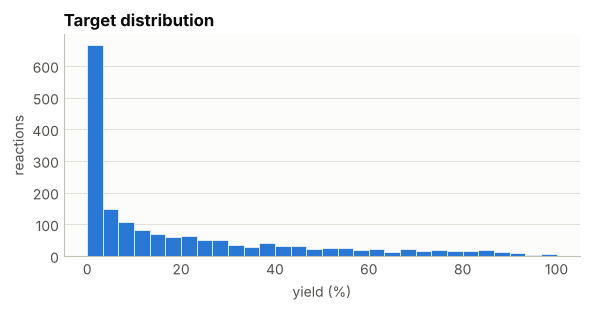

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


### 1.1 One descriptor per group of near-duplicates

Two descriptors that are near copies of each other (absolute correlation above 0.85) split one
effect between them arbitrarily, so a curve for either one is not identifiable. The pipeline
keeps the first descriptor of each group, the one the source paper names when there is one,
and drops the rest for every model.


In [4]:
PRUNE_R = 0.85
kept, dropped = prune_collinear(X, feature_names, PRUNE_R, keep_first=HYPOTHESIS)
for name, (partner, r) in dropped.items():
    print(f"dropped {name}: |r| = {r:.2f} with {partner}, which stays")
if not dropped:
    print(f"No pair of descriptors correlates above {PRUNE_R}; all {n_features} stay.")
X_df = X_df[kept]
feature_names = kept
X = X_df.to_numpy(dtype=float)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}
print(f"{n_features} descriptors go into every model.")


dropped ligand_hardness: |r| = 0.87 with ligand_E_LUMO, which stays
dropped base_E_HOMO: |r| = 0.90 with base_dipole, which stays
dropped base_E_LUMO: |r| = 1.00 with base_dipole, which stays
dropped solvent_E_LUMO: |r| = 0.99 with solvent_dipole, which stays
12 descriptors go into every model.


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?

The KAN carries light L1 and entropy penalties on its spline coefficients, at the same strength
(1e-3) in every notebook of the series. That strength was chosen once, on three of the datasets,
as the largest that cost no cross-validated accuracy: the benchmark stayed at R² 0.984, and the
deoxyfluorination and ligand sets improved. Ten times more cost accuracy on both regression sets.


Model                  r2               other
MLR                    0.277 ± 0.045   16.712 ± 0.804 (mae)
Random Forest          0.869 ± 0.020   4.892 ± 0.349 (mae)
Gradient Boosting      0.892 ± 0.018   4.889 ± 0.275 (mae)
KAN                    0.863 ± 0.021   5.869 ± 0.429 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = -0.0290 ± 0.0128, KAN better in 0/15, Wilcoxon p = 6.1e-05
(212 s)


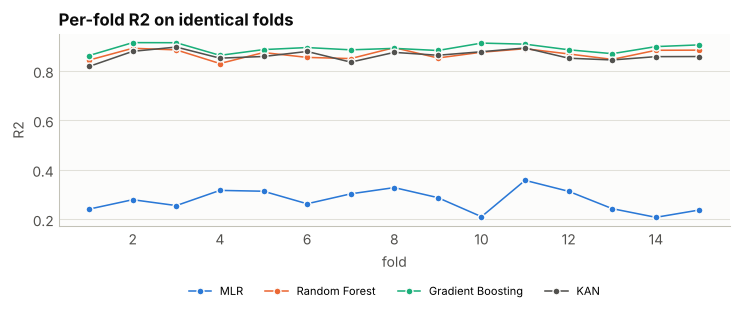

In [5]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_REG = 1e-3  # L1 and entropy penalty on the spline coefficients
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(
        layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3, l1_spline=KAN_REG, entropy_reg=KAN_REG
    )


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 1382 train / 346 test


,Test R2,Test MAE
Model,,
MLR,0.242,16.994
Random Forest,0.843,5.142
Gradient Boosting,0.864,5.059
KAN,0.821,6.400


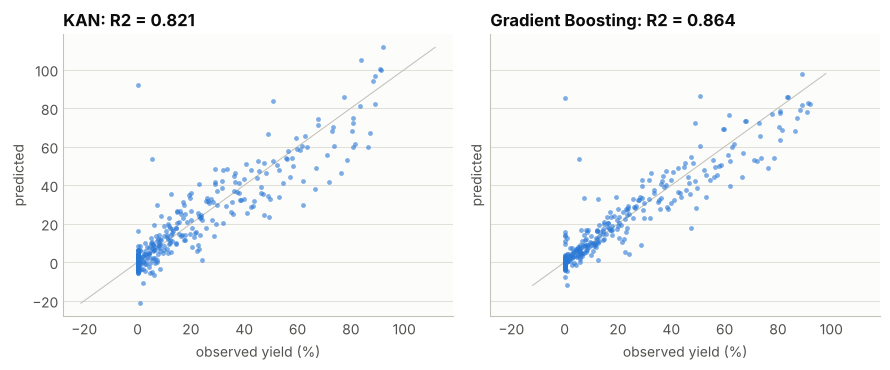

In [6]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


### 2.1 New molecules

The folds above split reactions at random, so almost every test reaction uses molecules the
models have already seen in other combinations. A chemist usually wants something harder: a
prediction for a molecule that was never run. Here every fold holds out whole molecules (named
below), three times with reshuffled groups, and the same four models are scored again, next to a model that knows nothing about the molecule
(the training mean, or the class prior). On held-out molecules that blank model is the line to clear.
R² can swing wildly when a held-out group has little spread of its own, so the mean absolute error
(or accuracy) is shown beside it.


Holding out whole ligands: 12 of them, about a fifth per fold.


Model                  r2               other
Training mean          -1.489 ± 3.795   21.385 ± 6.053 (mae)
MLR                    -8.767 ± 17.648   37.729 ± 12.271 (mae)
Random Forest          -5.512 ± 14.666   28.775 ± 9.587 (mae)
Gradient Boosting      -4.465 ± 10.183   29.202 ± 7.990 (mae)
KAN                    -18.801 ± 37.355   51.032 ± 25.294 (mae)
KAN vs Training mean, paired over 15 folds: Δr2 = -17.3121 ± 33.8607, KAN better in 0/15, Wilcoxon p = 6.1e-05
(197 s)


,"random folds, r2","new ligands, r2","random folds, mae","new ligands, mae"
Training mean,NaN,-1.489,NaN,21.385
MLR,0.277,-8.767,16.712,37.729
Random Forest,0.869,-5.512,4.892,28.775
Gradient Boosting,0.892,-4.465,4.889,29.202
KAN,0.863,-18.801,5.869,51.032


Models that beat the training mean on new ligands (R2): none


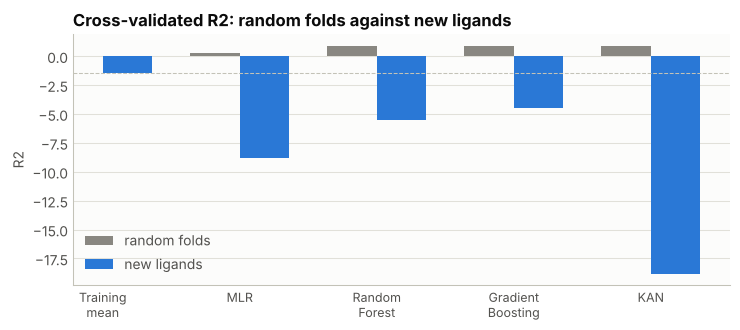

In [7]:
groups = np.asarray(GROUPS)
print(f"Holding out whole {GROUP_NAME}s: {len(np.unique(groups))} of them, about a fifth per fold.")
from sklearn.dummy import DummyClassifier, DummyRegressor

# A model that knows nothing about the molecule: the training mean, or the class prior.
# On held-out molecules it is the line every real model has to clear.
BLANK = "Training mean" if TASK == "regression" else "Class prior"
new_models = {BLANK: DummyRegressor() if TASK == "regression" else DummyClassifier(strategy="prior")}
new_models.update(make_models())
t0 = time.time()
new_result = cv_compare(
    new_models, X, y, task=TASK, n_splits=CV_SPLITS, n_repeats=CV_REPEATS,
    random_state=CV_SEED, fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}}, groups=groups,
    verbose=False,
)  # fmt: skip
print(new_result)
print(f"({time.time() - t0:.0f} s)")
m = cv_result.metric
other = "mae" if TASK == "regression" else "accuracy"
both = pd.DataFrame(
    {
        f"random folds, {m}": cv_result.summary[m + "_mean"],
        f"new {GROUP_NAME}s, {m}": new_result.summary[m + "_mean"],
        f"random folds, {other}": cv_result.summary[other + "_mean"],
        f"new {GROUP_NAME}s, {other}": new_result.summary[other + "_mean"],
    },
    index=list(new_models),
)
display(both.round(3))
blank_score = new_result.summary.loc[BLANK, m + "_mean"]
clears = [n for n in make_models() if new_result.summary.loc[n, m + "_mean"] > blank_score]
print(f"Models that beat the {BLANK.lower()} on new {GROUP_NAME}s ({m.upper()}): {', '.join(clears) or 'none'}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
style_axes(ax)
pos = np.arange(len(both))
ax.bar(pos - 0.18, both[f"random folds, {m}"], width=0.36, color=MUTED, linewidth=0, label="random folds")
ax.bar(pos + 0.18, both[f"new {GROUP_NAME}s, {m}"], width=0.36, color=SERIES[0], linewidth=0, label=f"new {GROUP_NAME}s")
ax.axhline(blank_score, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xticks(pos)
ax.set_xticklabels([n.replace(" ", "\n") for n in both.index], fontsize=9)
ax.legend(frameon=False, fontsize=8)
finish_axes(ax, f"Cross-validated {m.upper()}: random folds against new {GROUP_NAME}s", "", m.upper())
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.653
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,ligand_pct_Vbur_P,82.967,0.690,0.743,0.667,0.517
1,ligand_E_LUMO,-0.014,0.651,0.590,0.451,0.850
2,ligand_molar_volume,2381.551,0.649,0.569,0.441,0.908
3,base_dipole,7.471,0.609,0.535,0.416,0.850
4,solvent_molar_volume,974.462,0.600,0.590,0.437,0.633
5,solvent_dipole,2.696,0.600,0.590,0.437,0.633
6,ligand_dipole,1.137,0.582,0.673,0.557,0.283
7,temperature_C,97.500,0.578,0.517,0.399,0.775
8,ligand_E_HOMO,-0.222,0.564,0.431,0.379,1.000
9,base_molar_volume,969.820,0.551,0.549,0.394,0.558


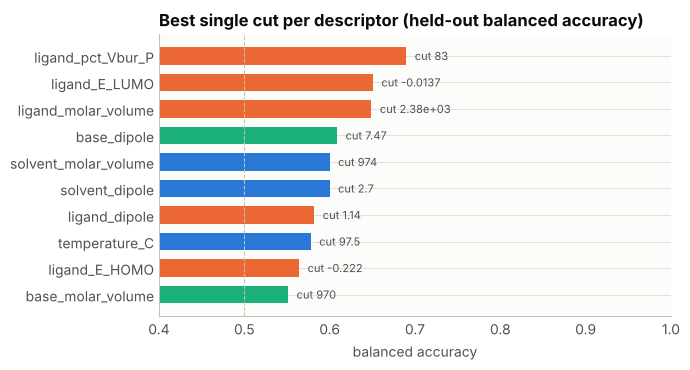

In [8]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Response curves, read as accumulated local effects

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors, among those with at least five
distinct values, then get a response curve in their own units.

The curve is an accumulated local effect rather than a partial effect. A partial effect holds
every other descriptor at its mean, which describes a compound that does not exist, and when
descriptors are correlated it asks the model about combinations it never saw. The accumulated
local effect moves a descriptor only within the reactions that already sit near each value and
adds up the local changes (Apley and Zhu, *J. R. Stat. Soc. B* 2020). The cell after the curves
puts the two readings side by side.

Each curve comes with the linear baseline read the same way, the envelope of five refits on
disjoint folds, and the observed values along the bottom. The curve is centred on the model's
mean prediction and adds up local changes, so at a sparsely sampled end it can leave the range of
the target: a probability curve that dips below zero there says "few reactions, still falling",
not that a probability is negative.


,Feature,Component,Sensitivity
0,ligand_dipole,ligand,84.4097
1,ligand_E_HOMO,ligand,57.7084
2,ligand_pct_Vbur_P,ligand,55.4861
3,ligand_molar_volume,ligand,51.6258
4,ligand_E_LUMO,ligand,36.6455
5,solvent_molar_volume,solvent,31.7485
6,solvent_dipole,solvent,21.6778
7,solvent_E_HOMO,solvent,20.9016
8,base_dipole,base,17.5234
9,base_molar_volume,base,11.6651


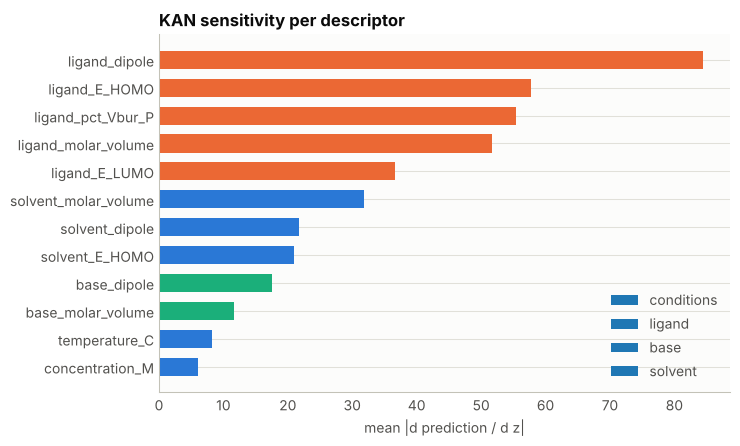

5 descriptors with at least 5 distinct values; 7 with fewer, shown as levels below.


curves and fold envelopes: 82 s


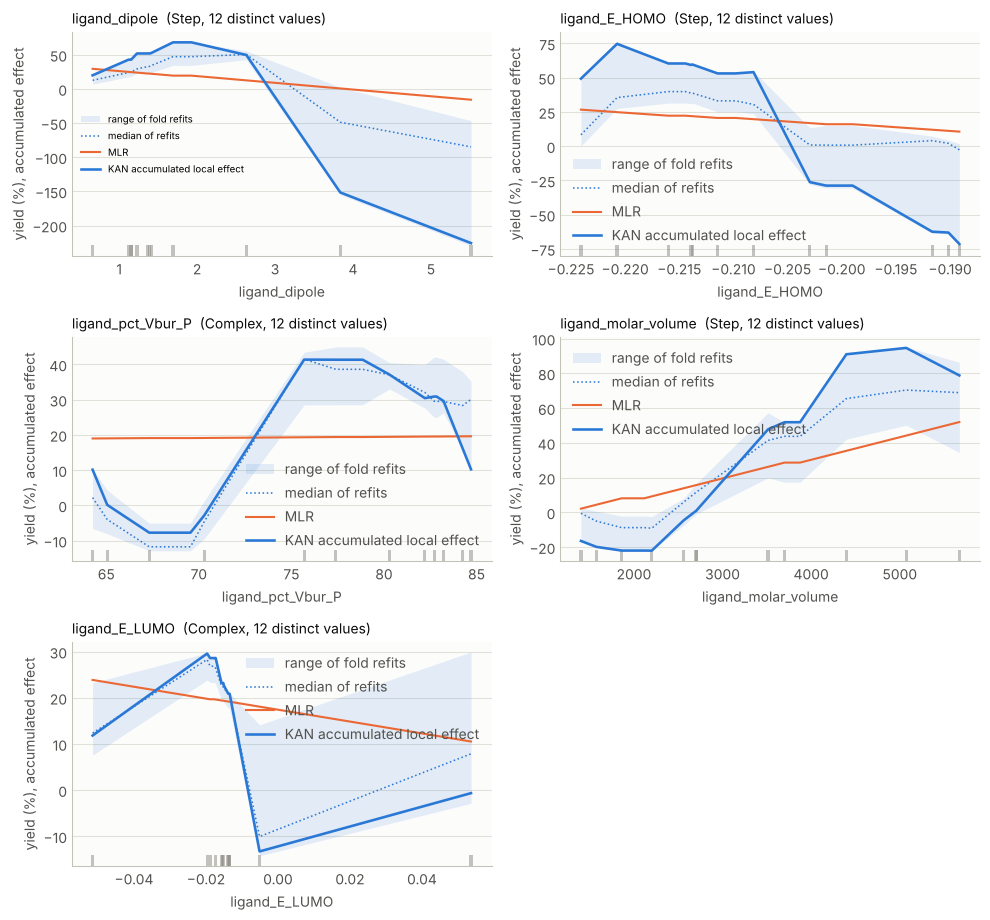

In [9]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in a later cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0
# An accumulated local effect is centred on the mean prediction and adds up local changes, so
# at a sparsely sampled end it can leave the range of the target (below 0 for a probability).
ALE_LABEL = f"{Y_LABEL}, accumulated effect"

t0 = time.time()
effects = accumulated_local_effects(
    kan, X, feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
effects = accumulated_local_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"curves and fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=ALE_LABEL)
    label = effects[f].shape(scale=SHAPE_SCALE)[0]
    ax.set_title(f"{f}  ({label}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


,Feature,Partial effect,Refits agreeing (PE),Accumulated local effect,Refits agreeing (ALE)
0,ligand_dipole,Window,0.8,Step,0.4
1,ligand_E_HOMO,Linear,0.2,Step,0.2
2,ligand_pct_Vbur_P,Step,0.4,Complex,0.2
3,ligand_molar_volume,Complex,0.6,Step,0.8
4,ligand_E_LUMO,Complex,0.4,Complex,1.0


Mean fraction of refits agreeing on the shape: partial effect 0.48, accumulated local effect 0.52


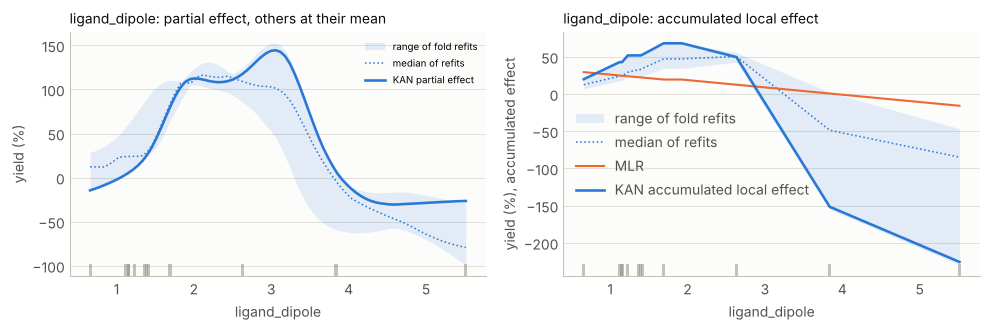

In [10]:
# The same KAN read both ways, with the same five refits behind each envelope.
pd_effects = partial_effects(kan, X, feature_names, top_features, scaler=scaler, task=TASK)
pd_effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=pd_effects, verbose=False,
)  # fmt: skip


def agreement(pe):
    """The full fit's shape label, and the fraction of refits that share it."""
    label = pe.shape(scale=SHAPE_SCALE)[0]
    folds = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
    return label, float(np.mean([lab == label for lab in folds]))


rows = []
for f in top_features:
    s_pe, a_pe = agreement(pd_effects[f])
    s_ale, a_ale = agreement(effects[f])
    rows.append(
        {
            "Feature": f,
            "Partial effect": s_pe,
            "Refits agreeing (PE)": a_pe,
            "Accumulated local effect": s_ale,
            "Refits agreeing (ALE)": a_ale,
        }
    )
reading_cmp = pd.DataFrame(rows)
display(reading_cmp.round(2))
print(
    f"Mean fraction of refits agreeing on the shape: partial effect "
    f"{reading_cmp['Refits agreeing (PE)'].mean():.2f}, accumulated local effect "
    f"{reading_cmp['Refits agreeing (ALE)'].mean():.2f}"
)

f0 = top_features[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
plot_partial_effect(axes[0], pd_effects[f0], ylabel=Y_LABEL)
plot_partial_effect(axes[1], effects[f0], ylabel=ALE_LABEL)
for ax, how in zip(axes, ["partial effect, others at their mean", "accumulated local effect"]):
    ax.set_title(f"{f0}: {how}", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


In [11]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


,Feature,Component,Level,Reactions,Observed mean,KAN mean prediction
0,temperature_C,conditions,90.000,576,13.725,14.140
1,temperature_C,conditions,105.000,576,20.336,19.309
2,temperature_C,conditions,120.000,576,24.064,24.588
3,concentration_M,conditions,0.057,576,18.080,17.148
4,concentration_M,conditions,0.100,576,19.587,19.482
5,concentration_M,conditions,0.153,576,20.457,21.159
6,base_dipole,base,7.169,432,16.002,16.535
7,base_dipole,base,7.773,432,21.531,20.769
8,base_dipole,base,10.148,432,22.801,22.604
9,base_dipole,base,11.011,432,17.165,17.187


Observed spread across the levels of each few-level descriptor:
Feature
solvent_molar_volume    17.5
solvent_dipole          17.5
solvent_E_HOMO          17.5
temperature_C           10.3
base_dipole              6.8
base_molar_volume        6.8
concentration_M          2.4


In [12]:
# Shape of the full fit, whether the five refits agree on it, and where its edges are.
# A curve whose range is under 5 % of the target's spread is "Constant" whatever its wiggles.
EDGED = {"Step", "Window", "Gap", "Saturating"}


def edge_range(values):
    values = [v for v in values if v is not None]
    if not values:
        return ""
    return f"{min(values):.3g} to {max(values):.3g} ({len(values)} of 5)"


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, _ = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        tr = transitions(pe.x_raw, pe.y)
        folds = [transitions(pe.x_raw, c) for c in pe.curves]
        edged = label in EDGED
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Rise": tr["rise"] if edged else None,
                "Fall": tr["fall"] if edged else None,
                "Rise in refits": edge_range([t["rise"] for t in folds]) if edged else "",
                "Fall in refits": edge_range([t["fall"] for t in folds]) if edged else "",
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: full fit {r.Shape}; refits {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Rise,Fall,Rise in refits,Fall in refits,Fold shapes
0,ligand_dipole,ligand,Step,0.443,0.4,0.336,NaN,3.401,1.42 to 1.52 (3 of 5),3.4 to 4.2 (5 of 5),"Step, Step, Inverted U, Window, Window"
1,ligand_E_HOMO,ligand,Step,0.360,0.2,1.020,NaN,-0.205,-0.222 to -0.222 (3 of 5),-0.207 to -0.199 (5 of 5),"Step, Window, Complex, Inverted U, Window"
2,ligand_pct_Vbur_P,ligand,Complex,0.773,0.2,0.275,NaN,NaN,,,"Complex, Step, Window, Step, Step"
3,ligand_molar_volume,ligand,Step,0.323,0.8,0.352,3315.122,NaN,2.85e+03 to 4.05e+03 (5 of 5),5.29e+03 to 5.29e+03 (1 of 5),"Step, Step, Step, Linear, Step"
4,ligand_E_LUMO,ligand,Complex,0.894,1.0,0.226,NaN,NaN,,,"Complex, Complex, Complex, Complex, Complex"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
  ligand_molar_volume: Step
  ligand_E_LUMO: Complex
Shapes that do not:
  ligand_dipole: full fit Step; refits Step, Step, Inverted U, Window, Window
  ligand_E_HOMO: full fit Step; refits Step, Window, Complex, Inverted U, Window
  ligand_pct_Vbur_P: full fit Complex; refits Complex, Step, Window, Step, Step


## 5. Check against the chemistry

Temperature is the one descriptor with a law behind it. If the reaction had a single
rate-limiting step with activation enthalpy $\Delta H^\ddagger$ and were far from completion,
$\ln(\text{yield})$ would be linear in $1/T$. The first panel tests that on the three
temperature levels with the group means. The next panels put the component group means (by name)
beside the KAN curves for the strongest base and solvent descriptors, which is how to tell a
descriptor effect from an identity effect when a component has four levels.


Arrhenius-type fit of the three temperature means: ln(yield) = 10.05 -2685/T
Apparent barrier from yields (not a measured activation energy): 5.3 kcal/mol


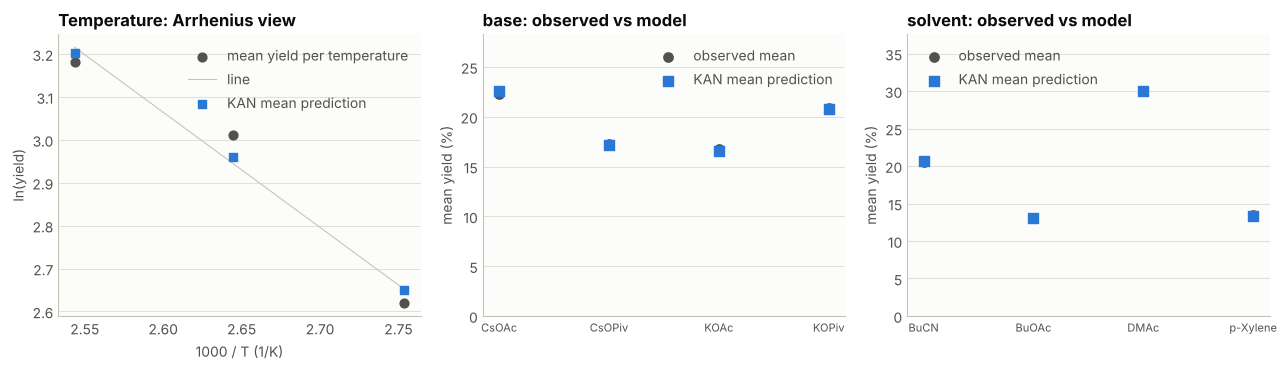

Mean yield by base and solvent (the CMD step involves the carboxylate):
solvent_file_name  BuCN  BuOAc  DMAc  p-Xylene
base_file_name                                
CsOAc              24.7   14.3  33.2      19.1
CsOPiv             21.6   11.4  23.9      11.7
KOAc               13.6   10.8  30.5       9.1
KOPiv              22.5   15.4  34.1      14.1

Mean yield by concentration and temperature:
Temp_C          90    105   120
Concentration                  
0.057          13.7  18.4  22.1
0.100          13.1  20.7  24.9
0.153          14.4  21.8  25.1


In [13]:
T = df["Temp_C"].to_numpy(dtype=float) + 273.15
gT = pd.DataFrame({"T": T, "yield": y}).groupby("T")["yield"].mean()
slope, intercept = np.polyfit(1.0 / gT.index.values, np.log(gT.values), 1)
print(f"Arrhenius-type fit of the three temperature means: ln(yield) = {intercept:.2f} {slope:+.0f}/T")
print(f"Apparent barrier from yields (not a measured activation energy): {-slope * 1.987e-3:.1f} kcal/mol")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
style_axes(ax)
ax.scatter(1000.0 / gT.index.values, np.log(gT.values), s=40, color=INK_2, zorder=3, label="mean yield per temperature")
xx = np.linspace(1000.0 / T.max(), 1000.0 / T.min(), 50)
ax.plot(xx, intercept + slope * xx / 1000.0, color=BASELINE, linewidth=PX, label="line")
mT = model_means(df["Temp_C"])
ax.scatter(1000.0 / (mT.index.to_numpy() + 273.15), np.log(mT.predicted), s=40, marker="s", color=SERIES[0], zorder=4, label="KAN mean prediction")
ax.legend(frameon=False, fontsize=7)
finish_axes(ax, "Temperature: Arrhenius view", "1000 / T (1/K)", "ln(yield)")

for ax, name_col in zip(axes[1:], ["base_file_name", "solvent_file_name"]):
    style_axes(ax)
    mm = model_means(df[name_col])
    ax.scatter(np.arange(len(mm)), mm.observed, s=45, color=INK_2, zorder=3, label="observed mean")
    ax.scatter(np.arange(len(mm)), mm.predicted, s=45, marker="s", color=SERIES[0], zorder=4, label="KAN mean prediction")
    ax.set_xticks(np.arange(len(mm)))
    ax.set_xticklabels(mm.index, fontsize=8)
    ax.set_ylim(0, max(mm.observed.max(), mm.predicted.max()) * 1.25)
    ax.legend(frameon=False, fontsize=7)
    finish_axes(ax, f"{name_col.split('_')[0]}: observed vs model", "", "mean yield (%)")
plt.tight_layout()
plt.show()

print("Mean yield by base and solvent (the CMD step involves the carboxylate):")
print(df.pivot_table(index="base_file_name", columns="solvent_file_name", values="yield", aggfunc="mean").round(1))
print("\nMean yield by concentration and temperature:")
print(df.pivot_table(index="Concentration", columns="Temp_C", values="yield", aggfunc="mean").round(1))


### Reading

The conditions behave as a rate law says they should. Of the ligand descriptors, only size
gives a curve that survives refitting, and it rests on twelve ligands.

**Pruning shows how little the base and solvent descriptors can say.** Four descriptors are
dropped as near-duplicates, among them the base LUMO, which correlates with the base dipole at
1.00. Four bases and four solvents are four labels each, whatever their descriptors are called.

**Temperature.** Mean yield rises 13.7, 20.3, 24.1 % over 90, 105 and 120 degrees, and a straight
line through ln(yield) against 1/T gives an apparent barrier near 5 kcal/mol. The KAN reproduces
the three level means to within about a point. This is an apparent barrier from fixed-time yields, not
a measured activation energy, and three temperatures can support a slope and nothing more.

**Concentration.** 18.1, 19.6, 20.5 % over a factor of 2.7 in concentration: nearly flat.

**Solvent and base.** DMAc gives 30.4 % mean yield against 13.0 % for butyl acetate. The base
effect depends on the counterion: potassium pivalate beats potassium acetate in all four solvents,
while cesium pivalate loses to cesium acetate in all four. The carboxylate sits in the concerted
metalation-deprotonation transition state and the cation sets how much of it is free in
solution, so a counterion-dependent ordering is mechanistically sensible, but with four bases it
remains an ordering of names.

**Ligands.** The spread is the largest effect in the dataset: 52.8 % for X-Phos and 50.2 % for
CgMe-PPh against 0.3 % for PPhMe2. The one ligand curve that four of five refits agree on is a
rise with molar volume, with its edge near 3300 bohr³ (2850 to 4050 across the refits). The five
ligands above it average 26.4 % and the seven below 14.4 %. Two exceptions show what twelve points
can and cannot say: CgMe-PPh is small and gives 50 %, and BrettPhos and JackiePhos are large and
give 18 to 26 %. The best single cut, on the buried volume at phosphorus at 83 %, reaches a
balanced accuracy of 0.69.

**The two readings barely differ here.** With twelve ligands neither reading is stable for most
descriptors: refits agree on the shape 48 % of the time with partial effects and 52 % with
accumulated local effects. The reading cannot add ligands that were not run.

**Models.** Gradient boosting reaches cross-validated R² 0.892, the random forest 0.869, the KAN
0.863 and the linear model 0.277. The KAN loses to gradient boosting in 15 folds of 15, by 0.029.

**No model predicts a new ligand.** Holding out whole ligands, a fifth of the twelve per fold,
every model does worse than predicting the training mean. Mean absolute error is 21.4 points for
the training mean, 28.8 for the random forest, 29.2 for gradient boosting, 37.7 for the linear
model and 51.0 for the KAN, which extrapolates furthest and loses to the mean in all 15 folds. Every
fit above, the ligand curves included, describes these twelve ligands and nothing beyond them.
With twelve, a ligand descriptor is close to a ligand name.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


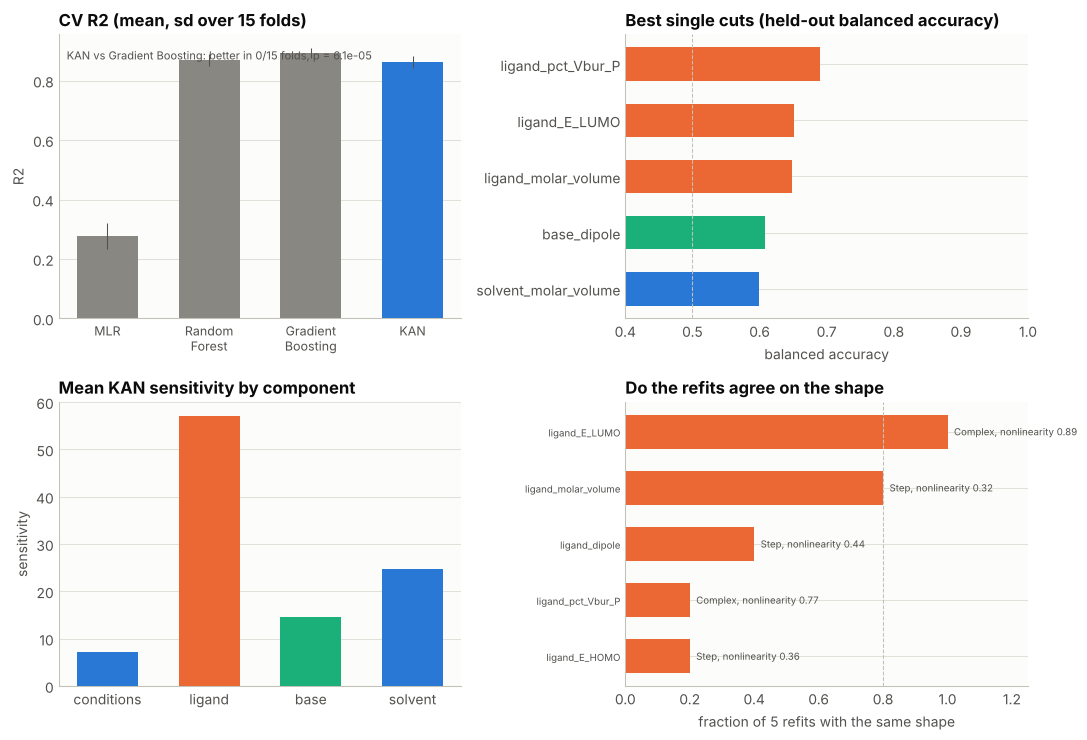

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9)
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
st = stab.sort_values(["Fold agreement", "Nonlinearity"])
ax.barh(st.Feature, st["Fold agreement"], color=[COMP_COLOR[c] for c in st.Component], height=0.6, linewidth=0)
ax.axvline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0, 1.25)
for yk, (a, nl, sh) in enumerate(zip(st["Fold agreement"], st["Nonlinearity"], st.Shape)):
    ax.text(a + 0.02, yk, f"{sh}, nonlinearity {nl:.2f}", va="center", fontsize=7, color=INK_2)
ax.tick_params(axis="y", labelsize=7)
finish_axes(ax, "Do the refits agree on the shape", "fraction of 5 refits with the same shape", "")
plt.tight_layout()
plt.show()
